In [1]:
from langgraph.graph import StateGraph, END, START
from typing import TypedDict, Literal
from pydantic import BaseModel, Field
from langchain_ollama import ChatOllama
import httpx

In [2]:
def print_workflow_info(workflow, app=None):
    """Print comprehensive information about a LangGraph workflow."""
    print("WORKFLOW INFORMATION")
    print("====================")
    print(f"Nodes: {workflow.nodes}")
    print(f"Edges: {workflow.edges}")

    try:
        finish_points = workflow.finish_points
        print(f"Finish points: {finish_points}")
    except:
        try:
            print(f"Finish point: {workflow._finish_point}")
        except:
            print("Finish points attribute not directly accessible")

    if app:
        print("\nWorkflow Visualization:")
        from IPython.display import display
        display(app.get_graph().draw_png())

In [3]:
client = httpx.Client(verify=False)
llm = ChatOllama(model="qwen3.5:9b", http_client=client)

In [4]:
class RouterState(TypedDict):
    user_input: str
    task_type: str
    output: str

In [5]:
class TaskType(BaseModel):
    task_type: Literal["summarize", "translate"]

In [6]:
class Router(BaseModel):
    role: str = Field(..., description="Decide whether the user wants to summarize a passage output 'summarize' or translate text into French output 'translate'. ")
llm_router = llm.bind_tools([Router]).with_structured_output(TaskType)

In [7]:
response = llm_router.invoke("translate this I love the sun its so warm into french")

In [8]:
response

TaskType(task_type='translate')

In [9]:
def router_node(state: RouterState) -> RouterState:
    routing_prompt = f"""
    You are an AI task classifier.

    Decide whether the user wants to:
    - "summarize" a passage
    - or "translate" text into French

    Respond with just one word: 'summarize' or 'translate'.

    User Input: "{state["user_input"]}"
    """

    response =  llm_router.invoke(routing_prompt)

    return {**state, "task_type": response.task_type}

In [10]:
def router(state: RouterState) -> str:
    return state['task_type']

In [11]:
def summarize_node(state: RouterState) -> RouterState:
    prompt = f"Please summarize the following passage:\n\n{state['user_input']}"
    response = llm.invoke(prompt)

    return {**state, "task_type": "summarize", "output":response.content}

In [12]:
def translate_node(state: RouterState) -> RouterState:
    prompt = f"Translate the following text to French:\n\n{state['user_input']}"
    response = llm.invoke(prompt)

    return {**state, "task_type": "translate", "output":response.content}

In [13]:
workflow = StateGraph(RouterState)

In [14]:
workflow.add_node("router", router_node)
workflow.add_node("summarize", summarize_node)
workflow.add_node("translate", translate_node)

In [15]:
workflow.set_entry_point("router")

In [16]:
workflow.add_conditional_edges("router", router, {
    "summarize": "summarize",
    "translate": "translate"
})

In [17]:
workflow.set_finish_point("summarize")
workflow.set_finish_point("translate")

In [18]:
app = workflow.compile()

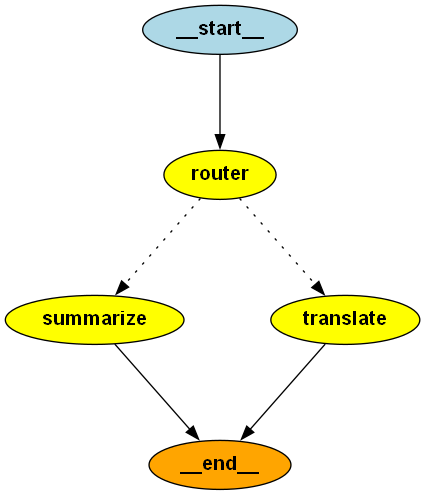

In [19]:
from IPython.display import Image, display

# Generate a visualization of the workflow graph
display(Image(app.get_graph().draw_png()))

In [20]:
input_text = {
        "user_input": "Can you translate this sentence: I love programming?"
    }

result = app.invoke(input_text)

In [21]:
print(result)

{'user_input': 'Can you translate this sentence: I love programming?', 'task_type': 'translate', 'output': ''}


In [22]:
input_text = {
        "user_input": "Can you summarize this sentence: I love programming so much it is the best thing ever. All I want to do is programming?"
    }

result = app.invoke(input_text)

In [23]:
result

{'user_input': 'Can you summarize this sentence: I love programming so much it is the best thing ever. All I want to do is programming?',
 'task_type': 'summarize',
 'output': "The passage expresses an intense passion for programming, stating that it is the speaker's favorite activity and their only desired pursuit."}

In [24]:
print(result[ 'output'])
print(result['task_type'])

The passage expresses an intense passion for programming, stating that it is the speaker's favorite activity and their only desired pursuit.
summarize
